# Estudo de Séries Temporais Meteorológicas – Bauru/SP (2010–2024)
## Metodologia KDD (Knowledge Discovery in Databases)

Este notebook consolida e documenta a execução interativa de cada etapa do processo KDD no estudo climático de Bauru/SP:
1. **Compreensão do Domínio**
2. **Seleção e Coleta de Dados**
3. **Pré-processamento e Limpeza**
4. **Transformação e Engenharia de Features**
5. **Mineração de Dados e Estatística**
6. **Interpretação e Avaliação**

In [1]:
import sys
from pathlib import Path

# Adiciona o diretório raiz ao path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from src.selection import fetch_raw_weather_data, save_raw_dataset
from src.preprocessing import run_preprocessing_pipeline
from src.transformation import run_transformation_pipeline
from src.mining import run_mining_pipeline
from src.visualization import generate_all_visualizations

print("Ambiente e módulos do projeto importados com sucesso!")

Ambiente e módulos do projeto importados com sucesso!


## 1. Carregando os Datasets Processados (Diário e Mensal)

In [2]:
df_daily = pd.read_parquet('../data/processed/bauru_weather_daily.parquet')
df_monthly = pd.read_parquet('../data/processed/bauru_weather_monthly.parquet')

print(f"Dataset Diário: {df_daily.shape[0]} registros x {df_daily.shape[1]} colunas")
print(f"Dataset Mensal: {df_monthly.shape[0]} registros x {df_monthly.shape[1]} colunas")
df_monthly.head()

Dataset Diário: 5480 registros x 24 colunas
Dataset Mensal: 181 registros x 16 colunas


,year,month,season,temp_mean,temp_min,temp_max,thermal_amplitude_mean,precipitation_total,rainy_days_count,max_consecutive_dry_days,humidity_mean,wind_speed_mean,temp_climatology_mean,precip_climatology_mean,temp_anomaly,precip_anomaly
2010-01-01,2010,1,Verão,24.581921,19.9495,31.8495,7.250000,273.1,26,2,81.894415,8.142269,24.484267,189.737500,0.097654,83.362500
2010-02-01,2010,2,Verão,25.586554,19.4995,32.9995,8.025000,103.5,13,5,75.937404,8.251683,24.798136,133.186667,0.788417,-29.686667
2010-03-01,2010,3,Outono,24.239285,17.3495,31.7995,7.933871,107.8,15,7,77.227180,9.007929,24.094449,135.333333,0.144836,-27.533333
2010-04-01,2010,4,Outono,21.981583,13.3995,31.1995,8.541667,48.1,5,17,72.769550,11.031132,22.710308,59.446667,-0.728725,-11.346667
2010-05-01,2010,5,Outono,19.603667,9.7495,29.8995,9.872581,28.6,6,13,70.454946,9.917625,20.104762,49.346667,-0.501096,-20.746667


## 2. Estatísticas Descritivas Globais

In [3]:
df_daily[['temp_mean', 'temp_min', 'temp_max', 'thermal_amplitude', 'precipitation_sum', 'consecutive_dry_days']].describe()

,temp_mean,temp_min,temp_max,thermal_amplitude,precipitation_sum,consecutive_dry_days
count,5480.000000,5480.000000,5480.000000,5480.000000,5480.000000,5480.000000
mean,22.510204,17.961719,28.111135,10.149416,3.015219,6.294708
std,3.169643,3.373726,3.564363,2.935896,6.406040,10.301966
min,9.060417,3.500000,13.600000,1.400000,0.000000,0.000000
25%,20.483208,15.649500,25.900000,8.250000,0.000000,0.000000
50%,22.910417,18.500000,28.349500,10.300000,0.000000,2.000000
75%,24.727479,20.650000,30.549500,12.100000,2.900000,8.000000
max,31.564583,26.300000,39.700000,19.450000,67.600000,71.000000


## 3. Resultados dos Testes Estatísticos (Mineração de Dados)

In [4]:
with open('../reports/tables/statistical_tests.json', 'r') as f:
    stats_report = json.load(f)

print("--- Teste de Tendência de Mann-Kendall ---")
for t in stats_report['mann_kendall_trends']:
    print(f"{t['variable']}: Tendência={t['trend']} | p-value={t['hypothesis_p_value']:.4f} | Sens slope={t['sens_slope']:.4f}")

print("\n--- Comparação Interdecadal de Estiagem ---")
sub = stats_report['subperiod_comparison']
print(f"Período 1 (2010-2016): Máx de dias secos consecutivos = {sub['consecutive_dry_days_max']['period_1_max']}")
print(f"Período 2 (2017-2024): Máx de dias secos consecutivos = {sub['consecutive_dry_days_max']['period_2_max']}")
print(f"Significância Estatística (Mann-Whitney U): p = {sub['consecutive_dry_days_max']['mann_whitney_p_value']:.2e}")

--- Teste de Tendência de Mann-Kendall ---
Temperatura Média Mensal: Tendência=no trend | p-value=0.5667 | Sens slope=0.0017
Temperatura Máxima Mensal: Tendência=no trend | p-value=0.0783 | Sens slope=0.0076
Temperatura Mínima Mensal: Tendência=no trend | p-value=0.4943 | Sens slope=-0.0049
Precipitação Total Mensal: Tendência=no trend | p-value=0.1480 | Sens slope=-0.1272
Máximo de Dias Secos Consecutivos: Tendência=no trend | p-value=0.4859 | Sens slope=0.0000

--- Comparação Interdecadal de Estiagem ---
Período 1 (2010-2016): Máx de dias secos consecutivos = 64
Período 2 (2017-2024): Máx de dias secos consecutivos = 71
Significância Estatística (Mann-Whitney U): p = 1.37e-08


## 4. Visualizações Principais do Estudo

Exibindo: ../reports/figures/fig01_climograma_bauru.png


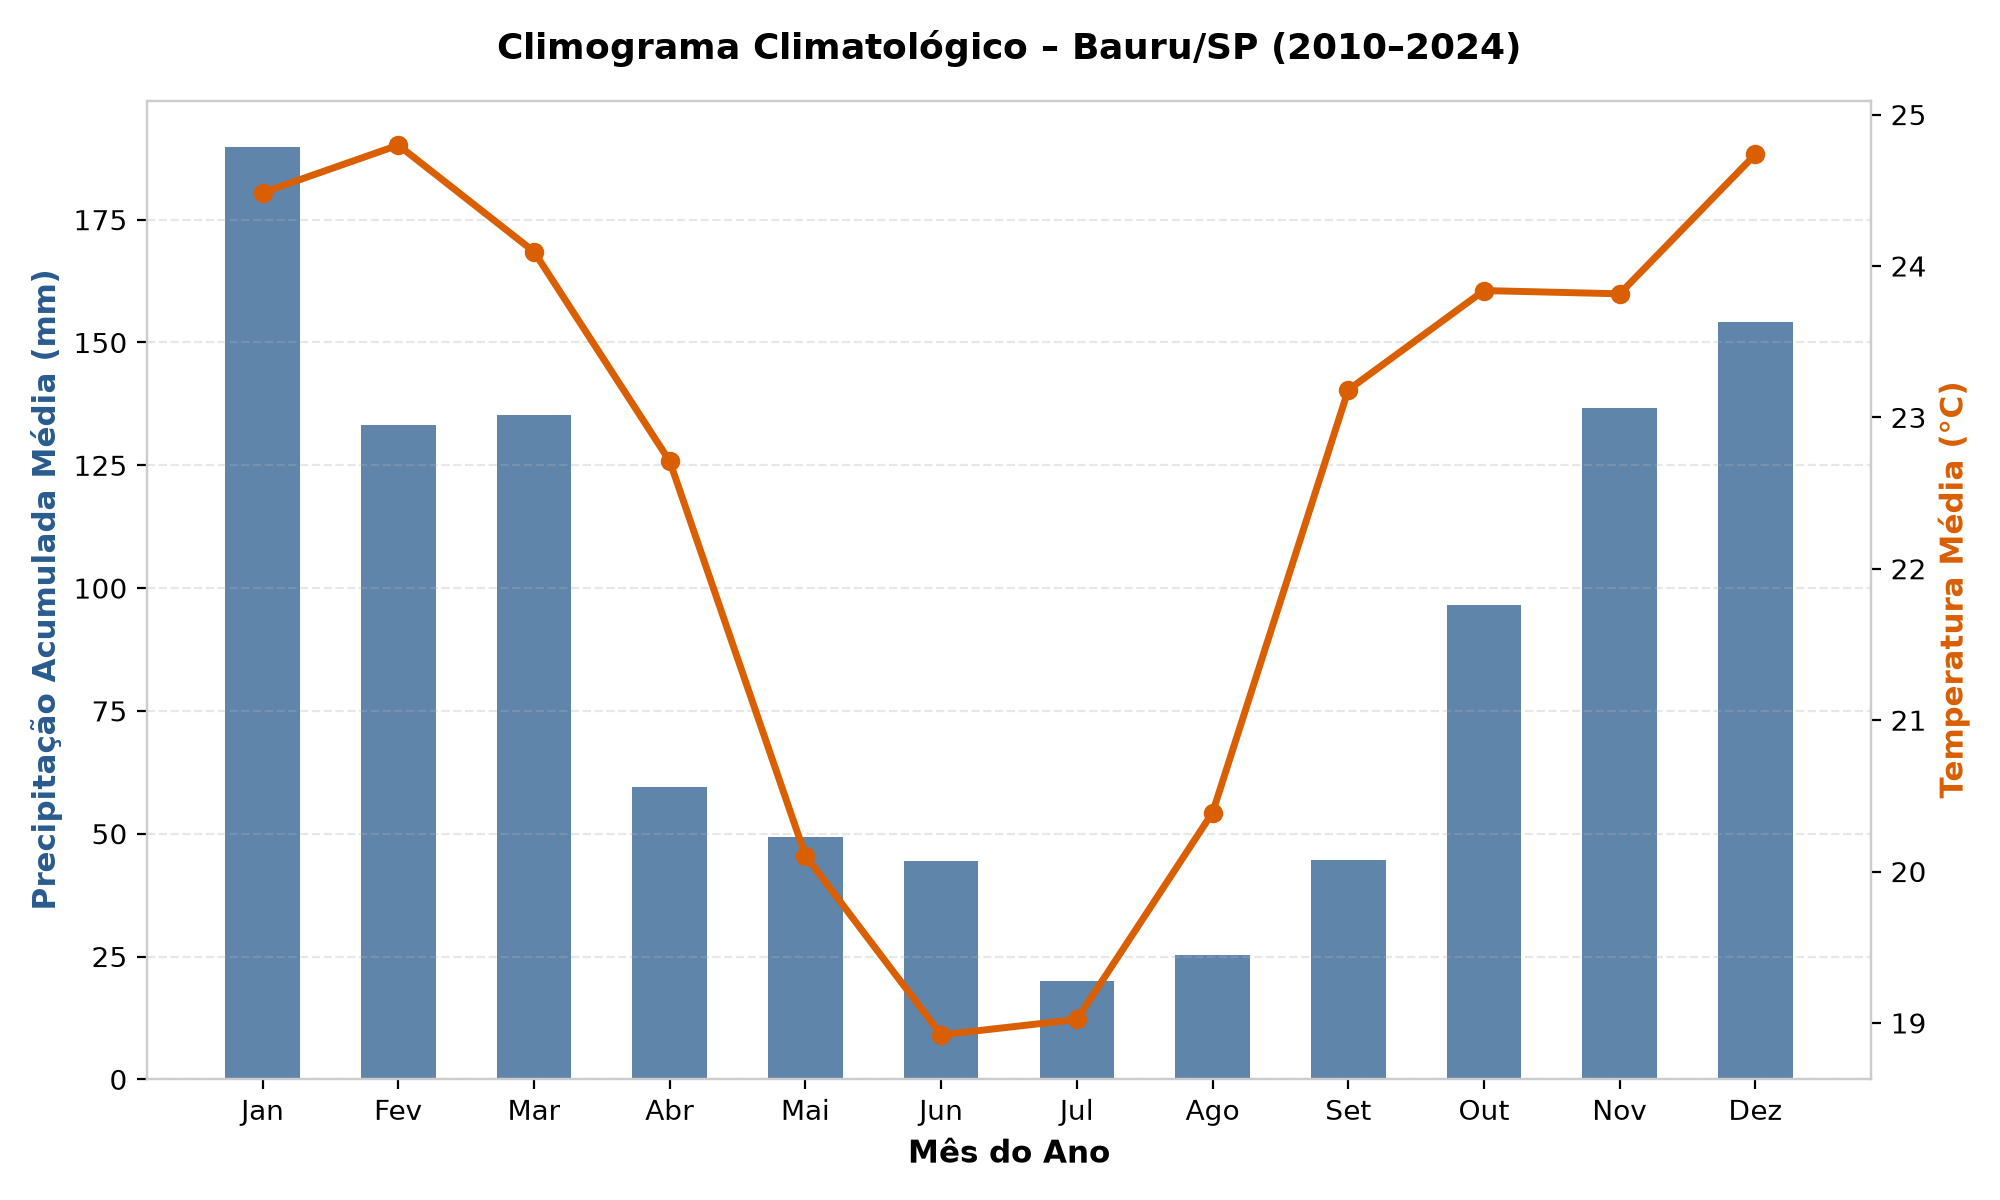

Exibindo: ../reports/figures/fig02_anomalias_temperatura.png


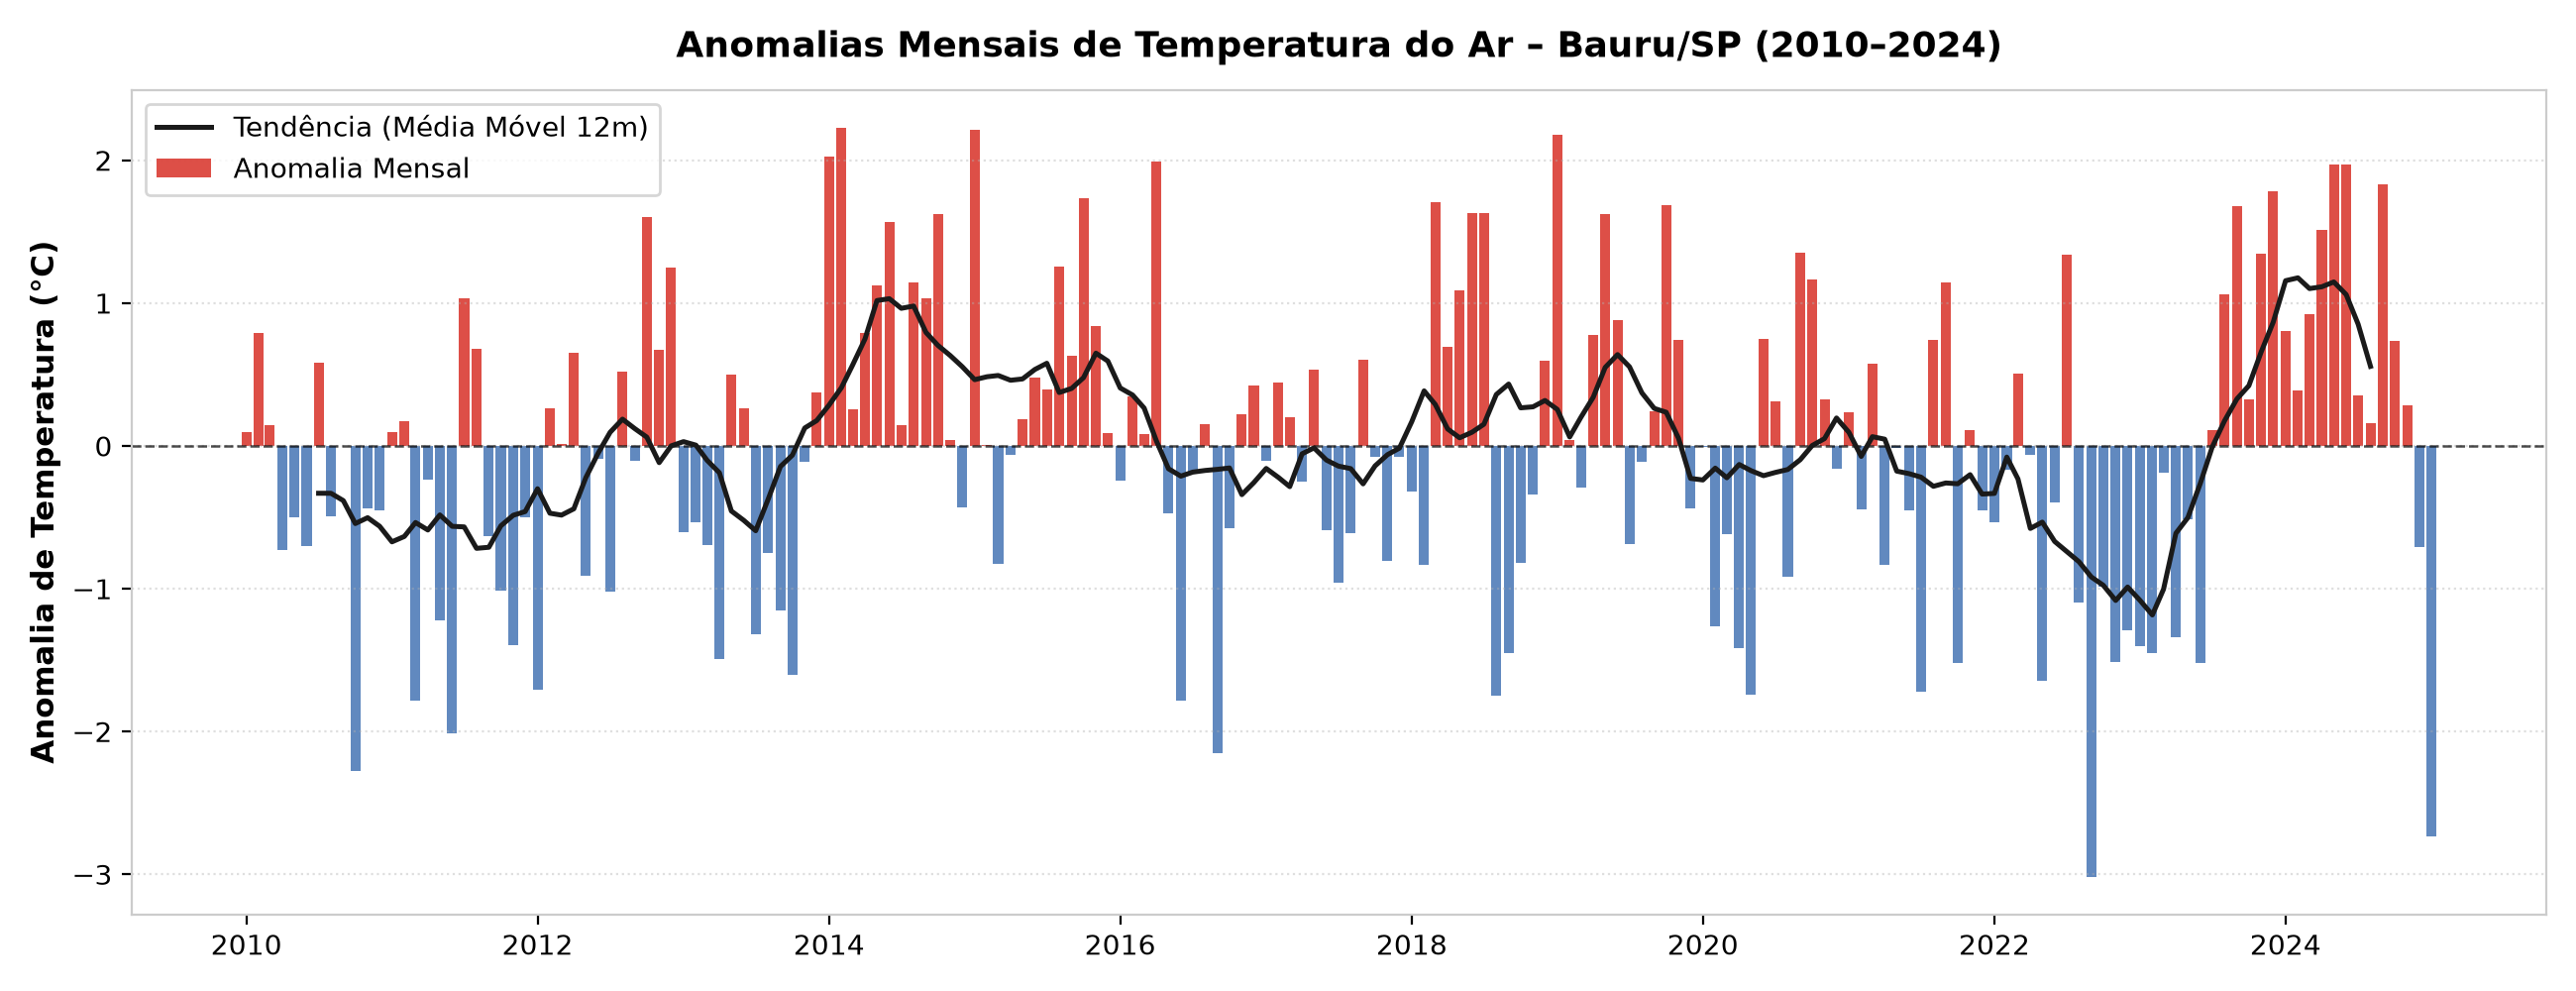

Exibindo: ../reports/figures/fig03_boxplots_temperatura_mensal.png


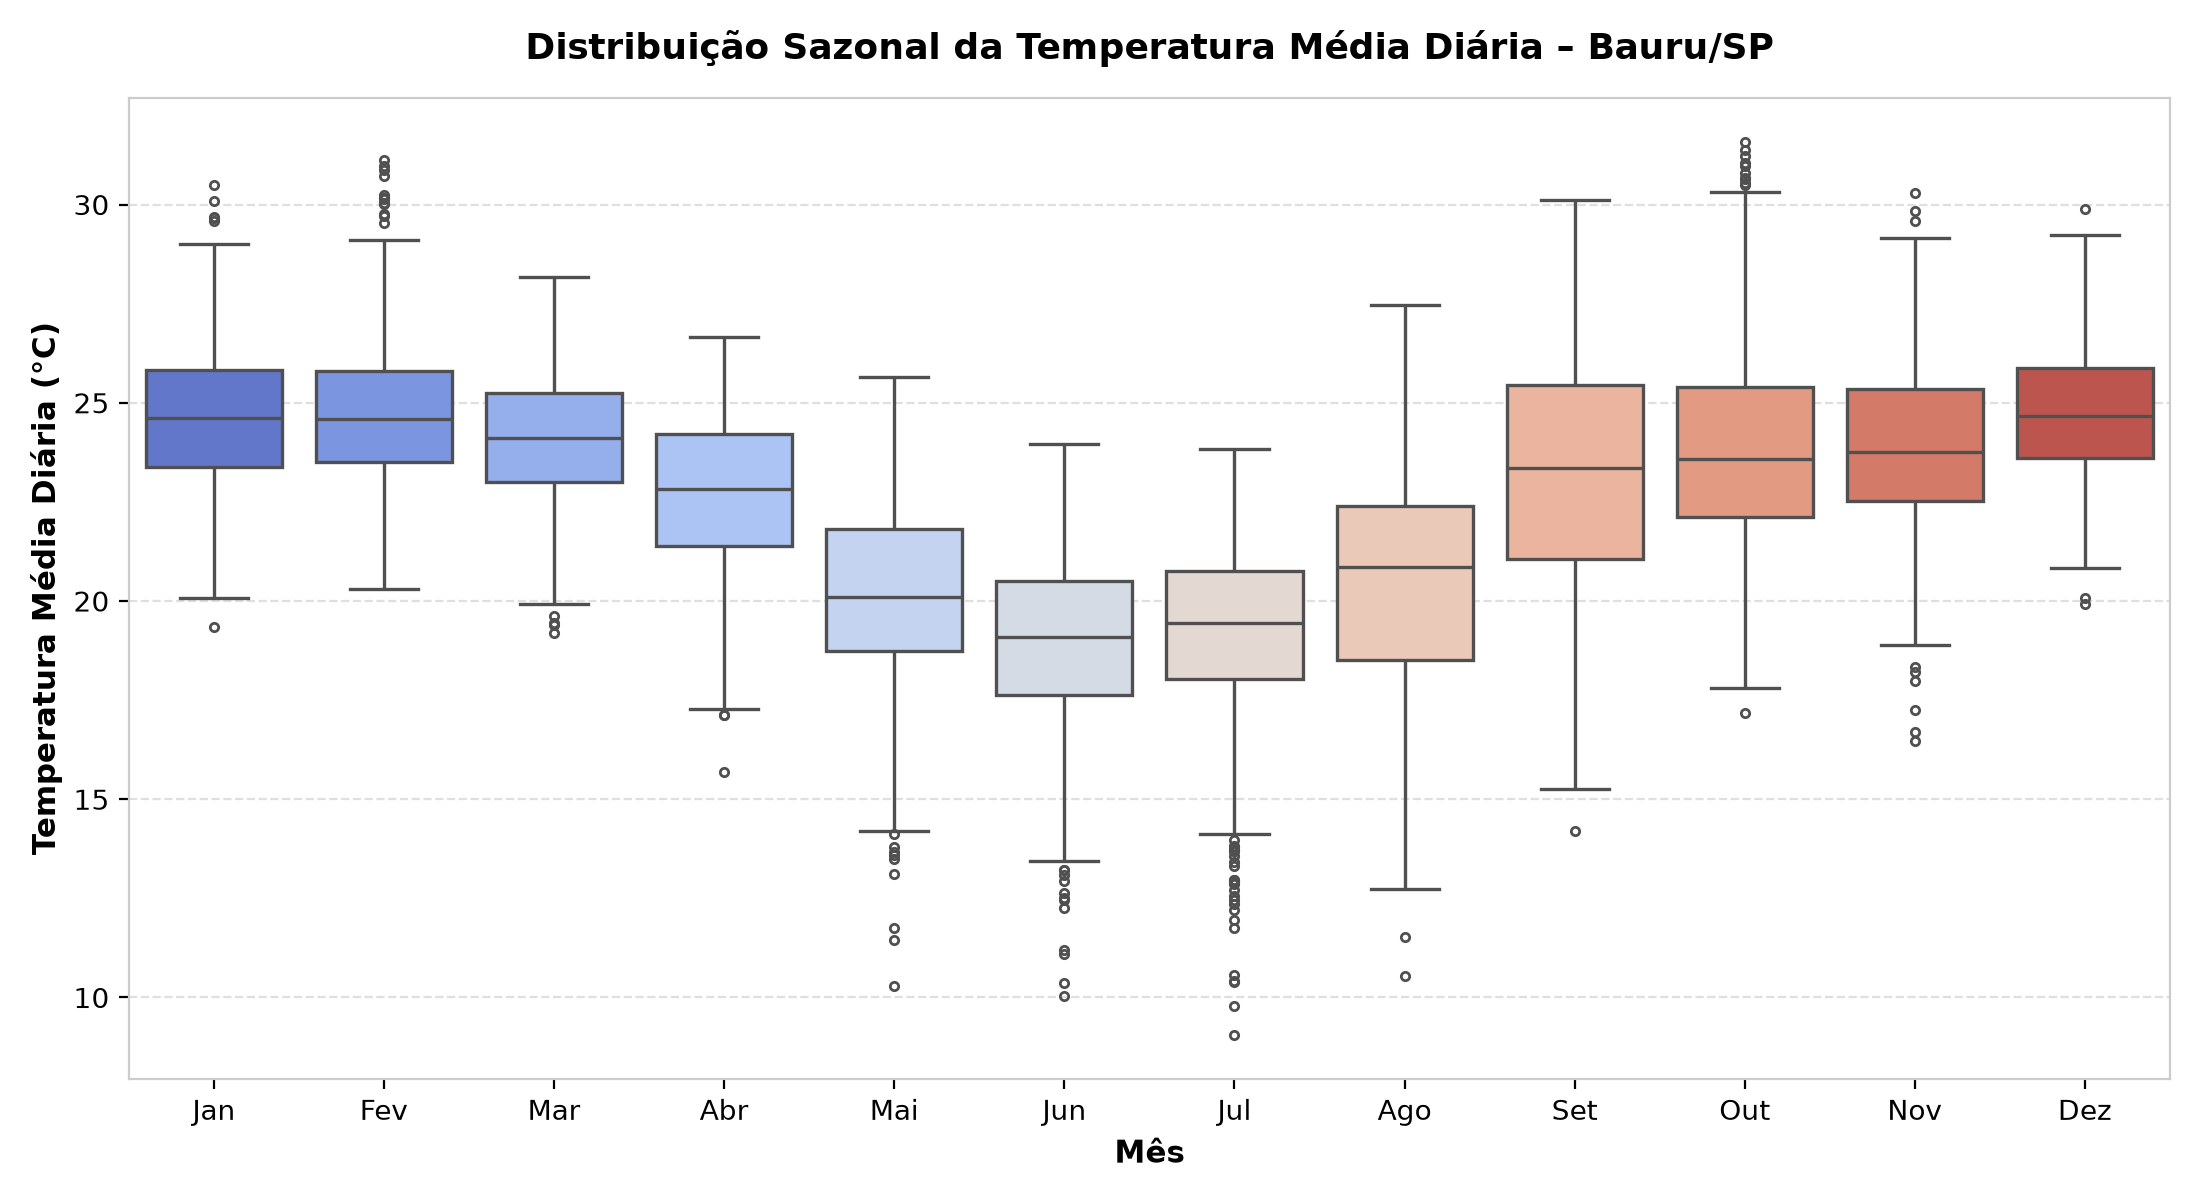

Exibindo: ../reports/figures/fig04_heatmap_correlacoes.png


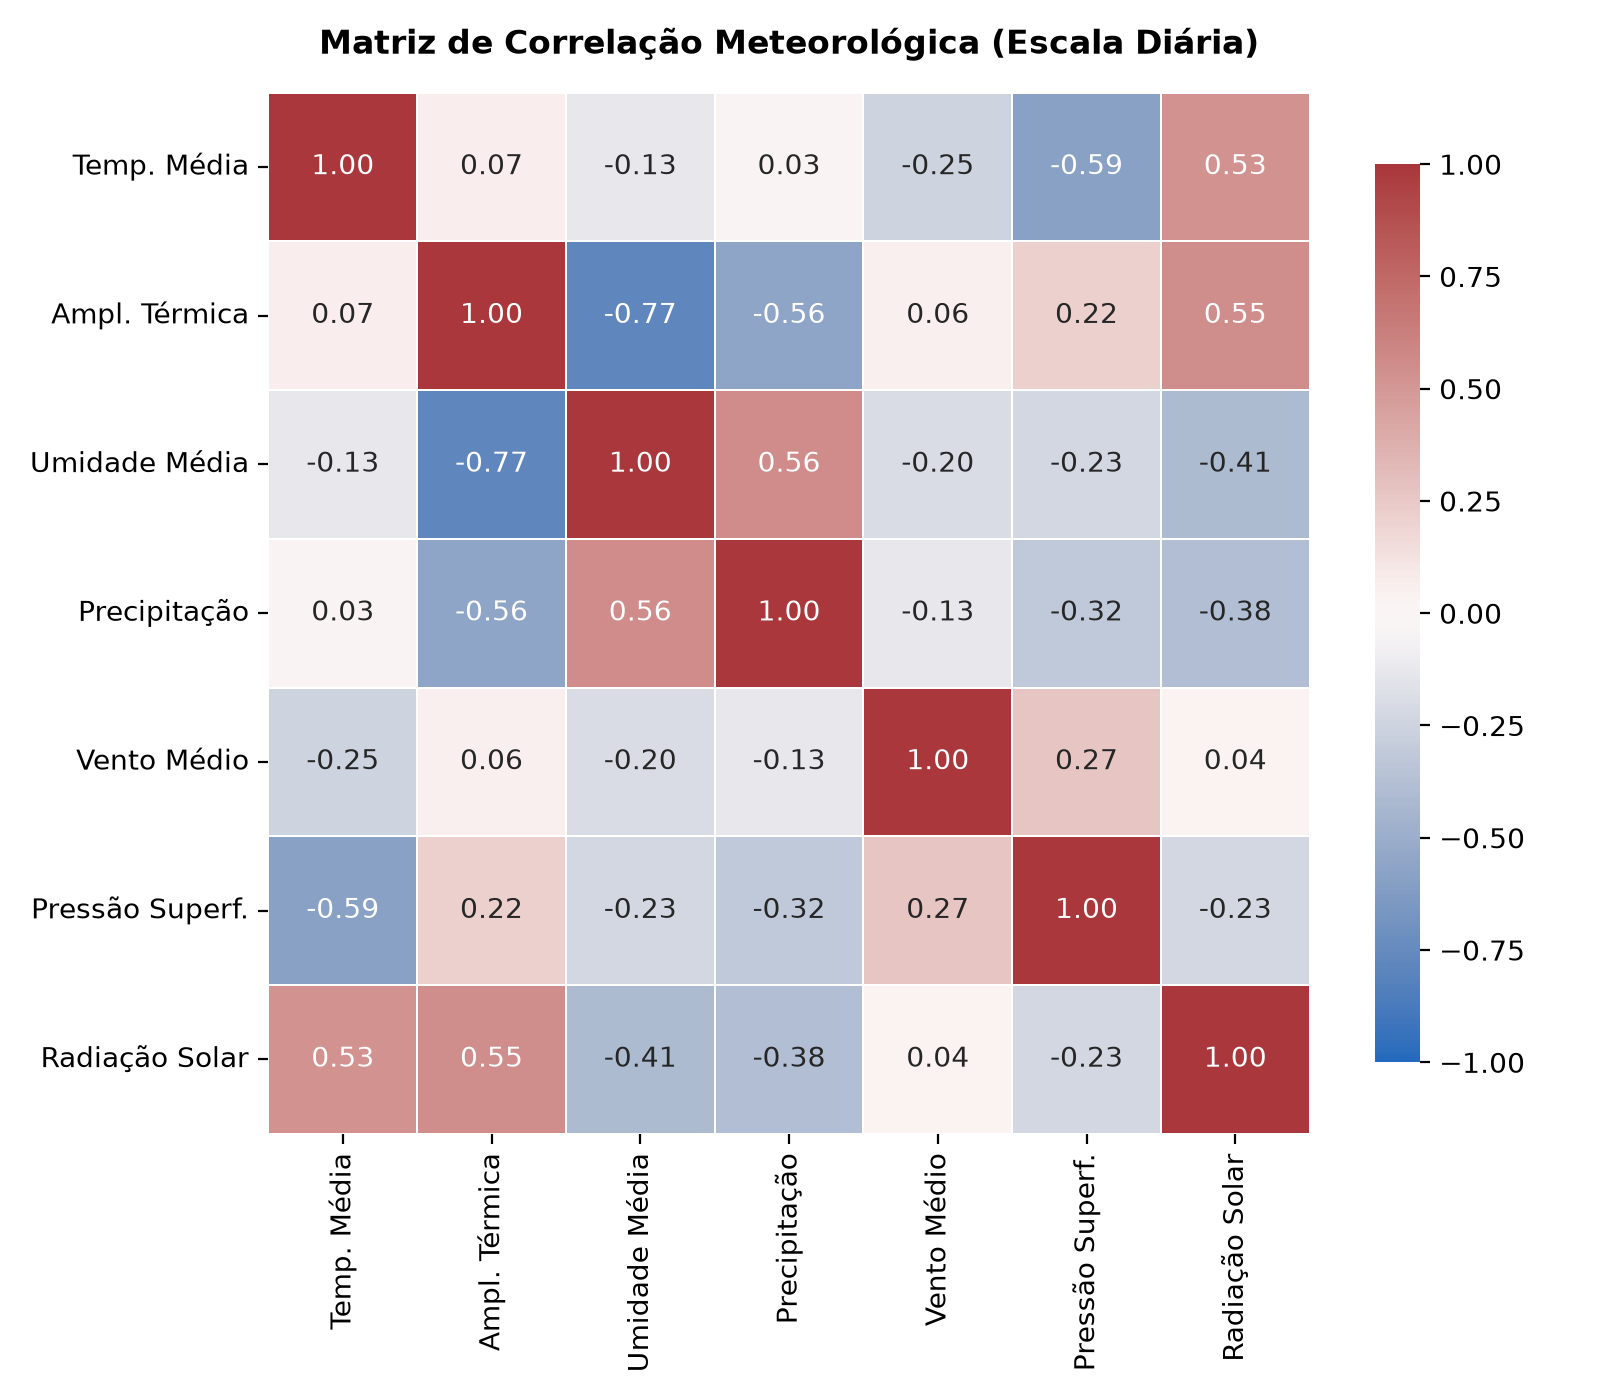

Exibindo: ../reports/figures/fig05_decomposicao_stl_temperatura.png


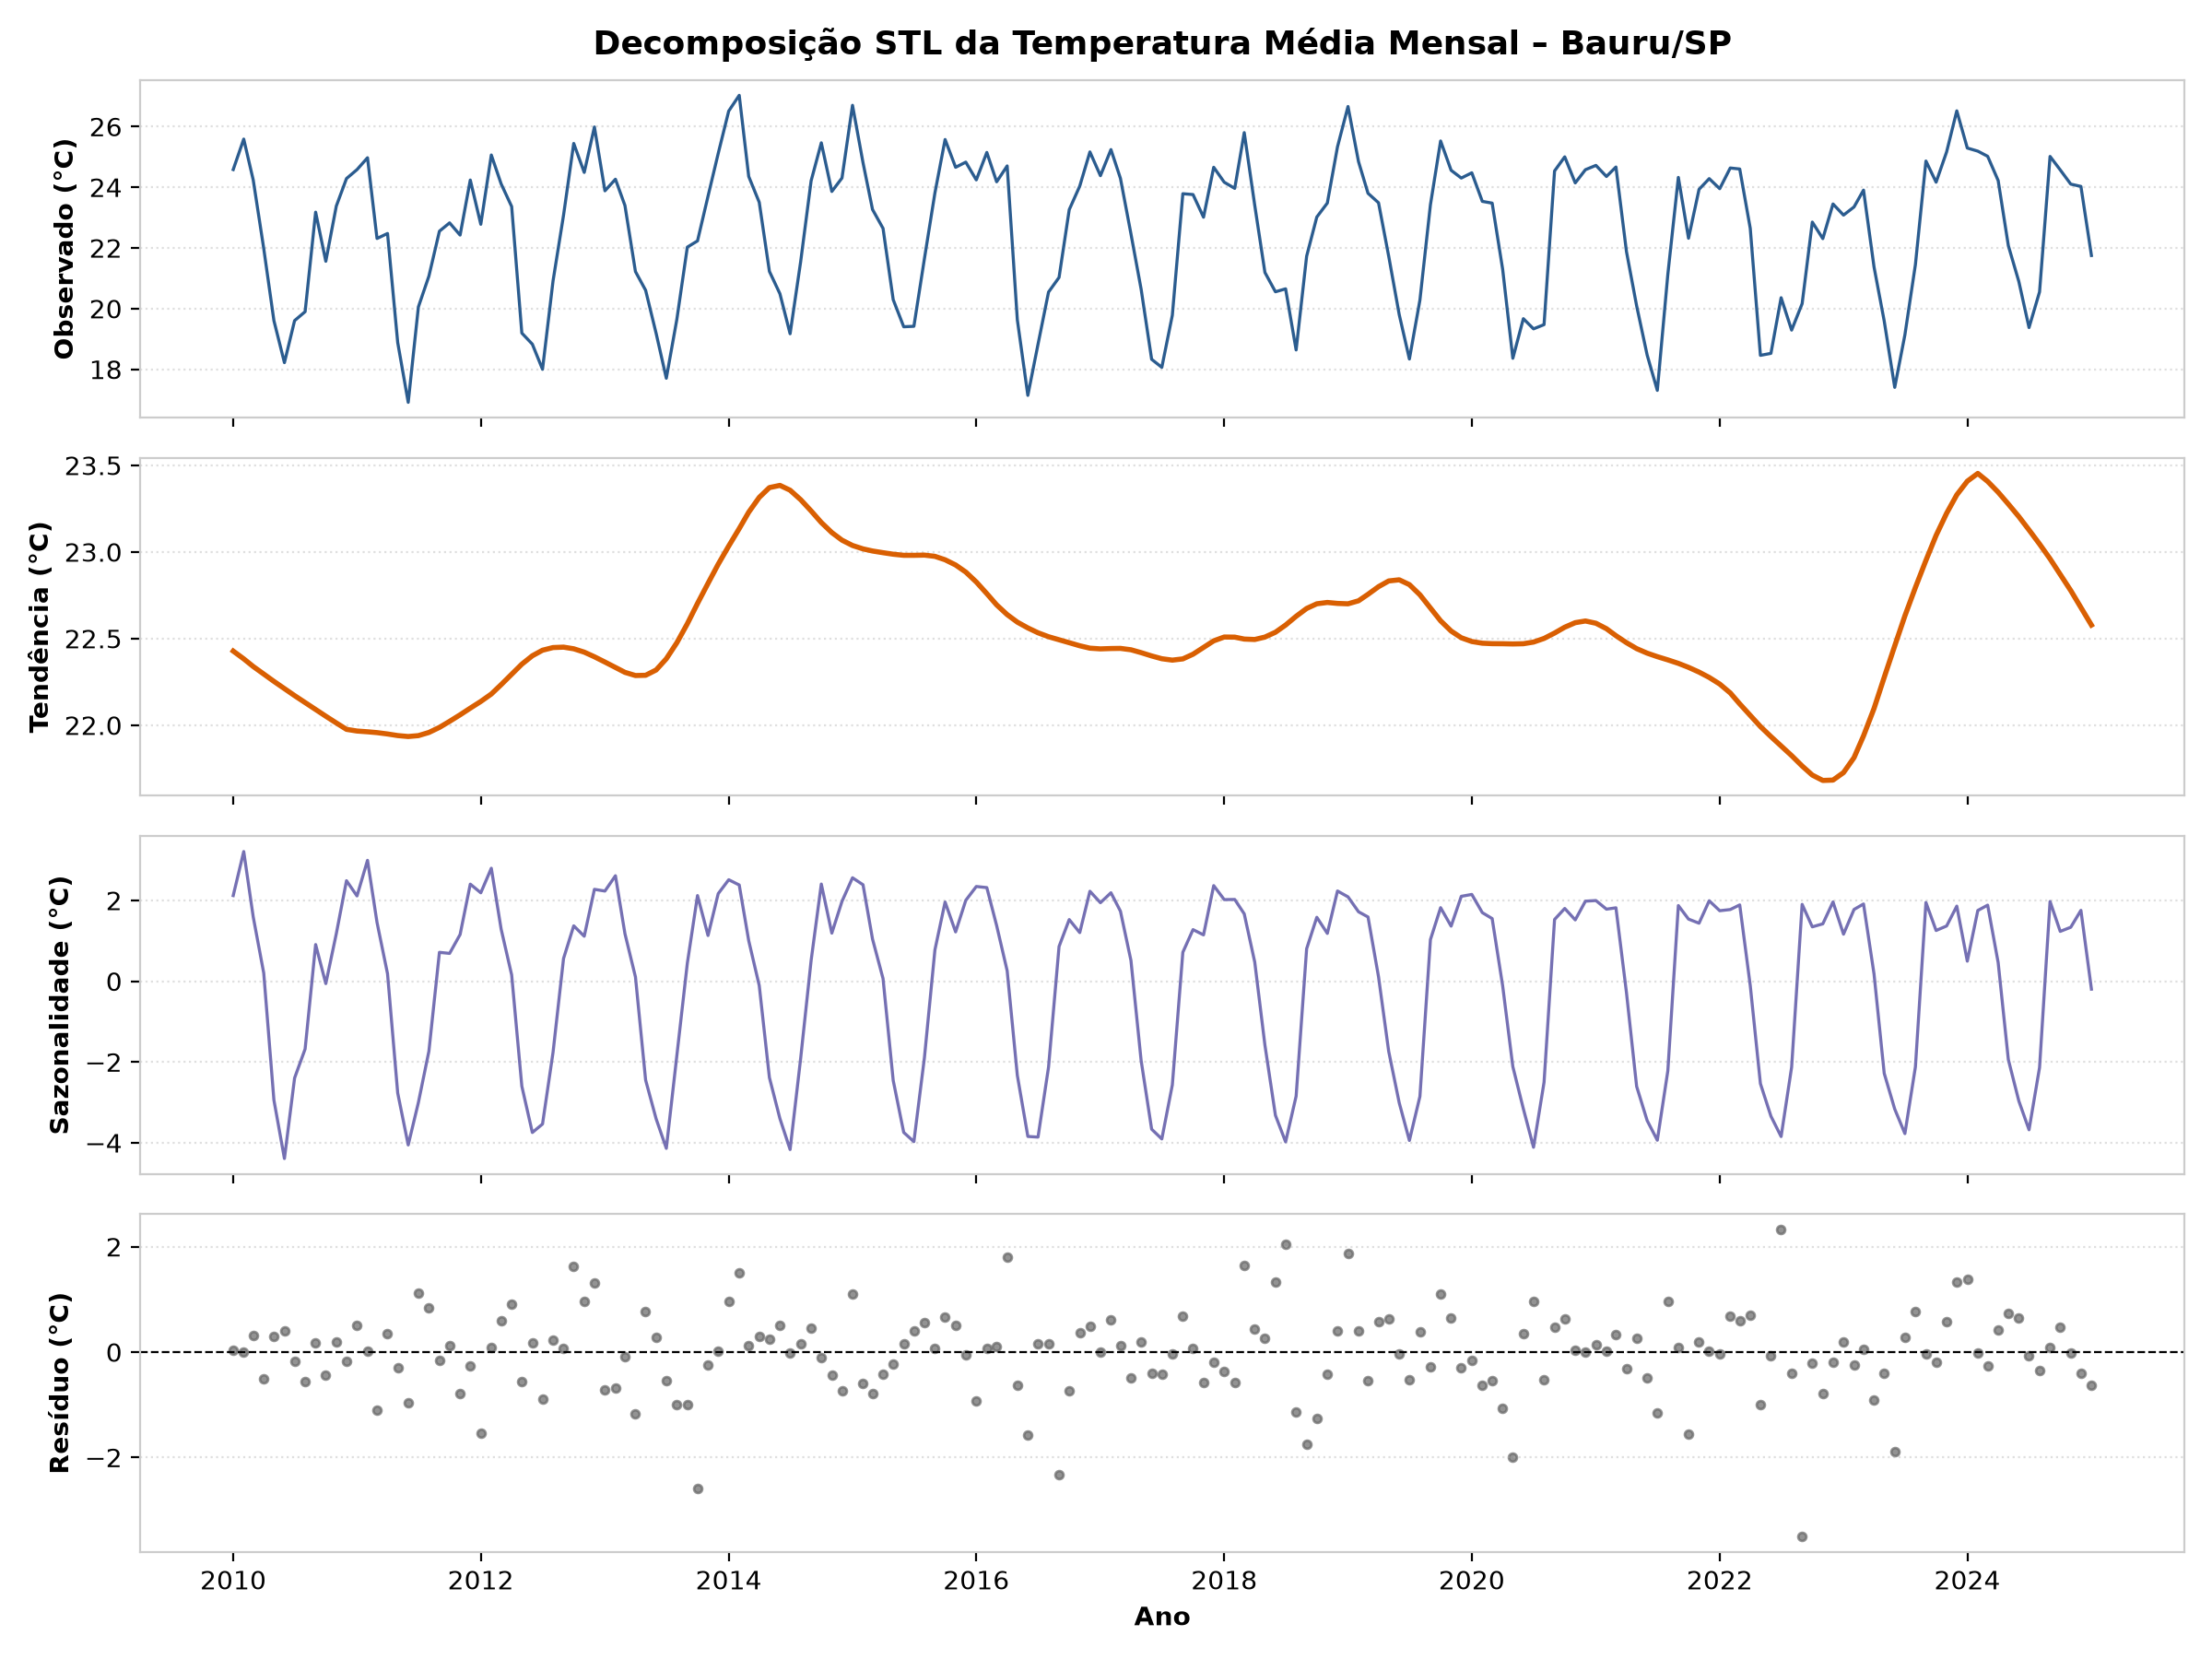

Exibindo: ../reports/figures/fig06_eventos_estiagem_dias_secos.png


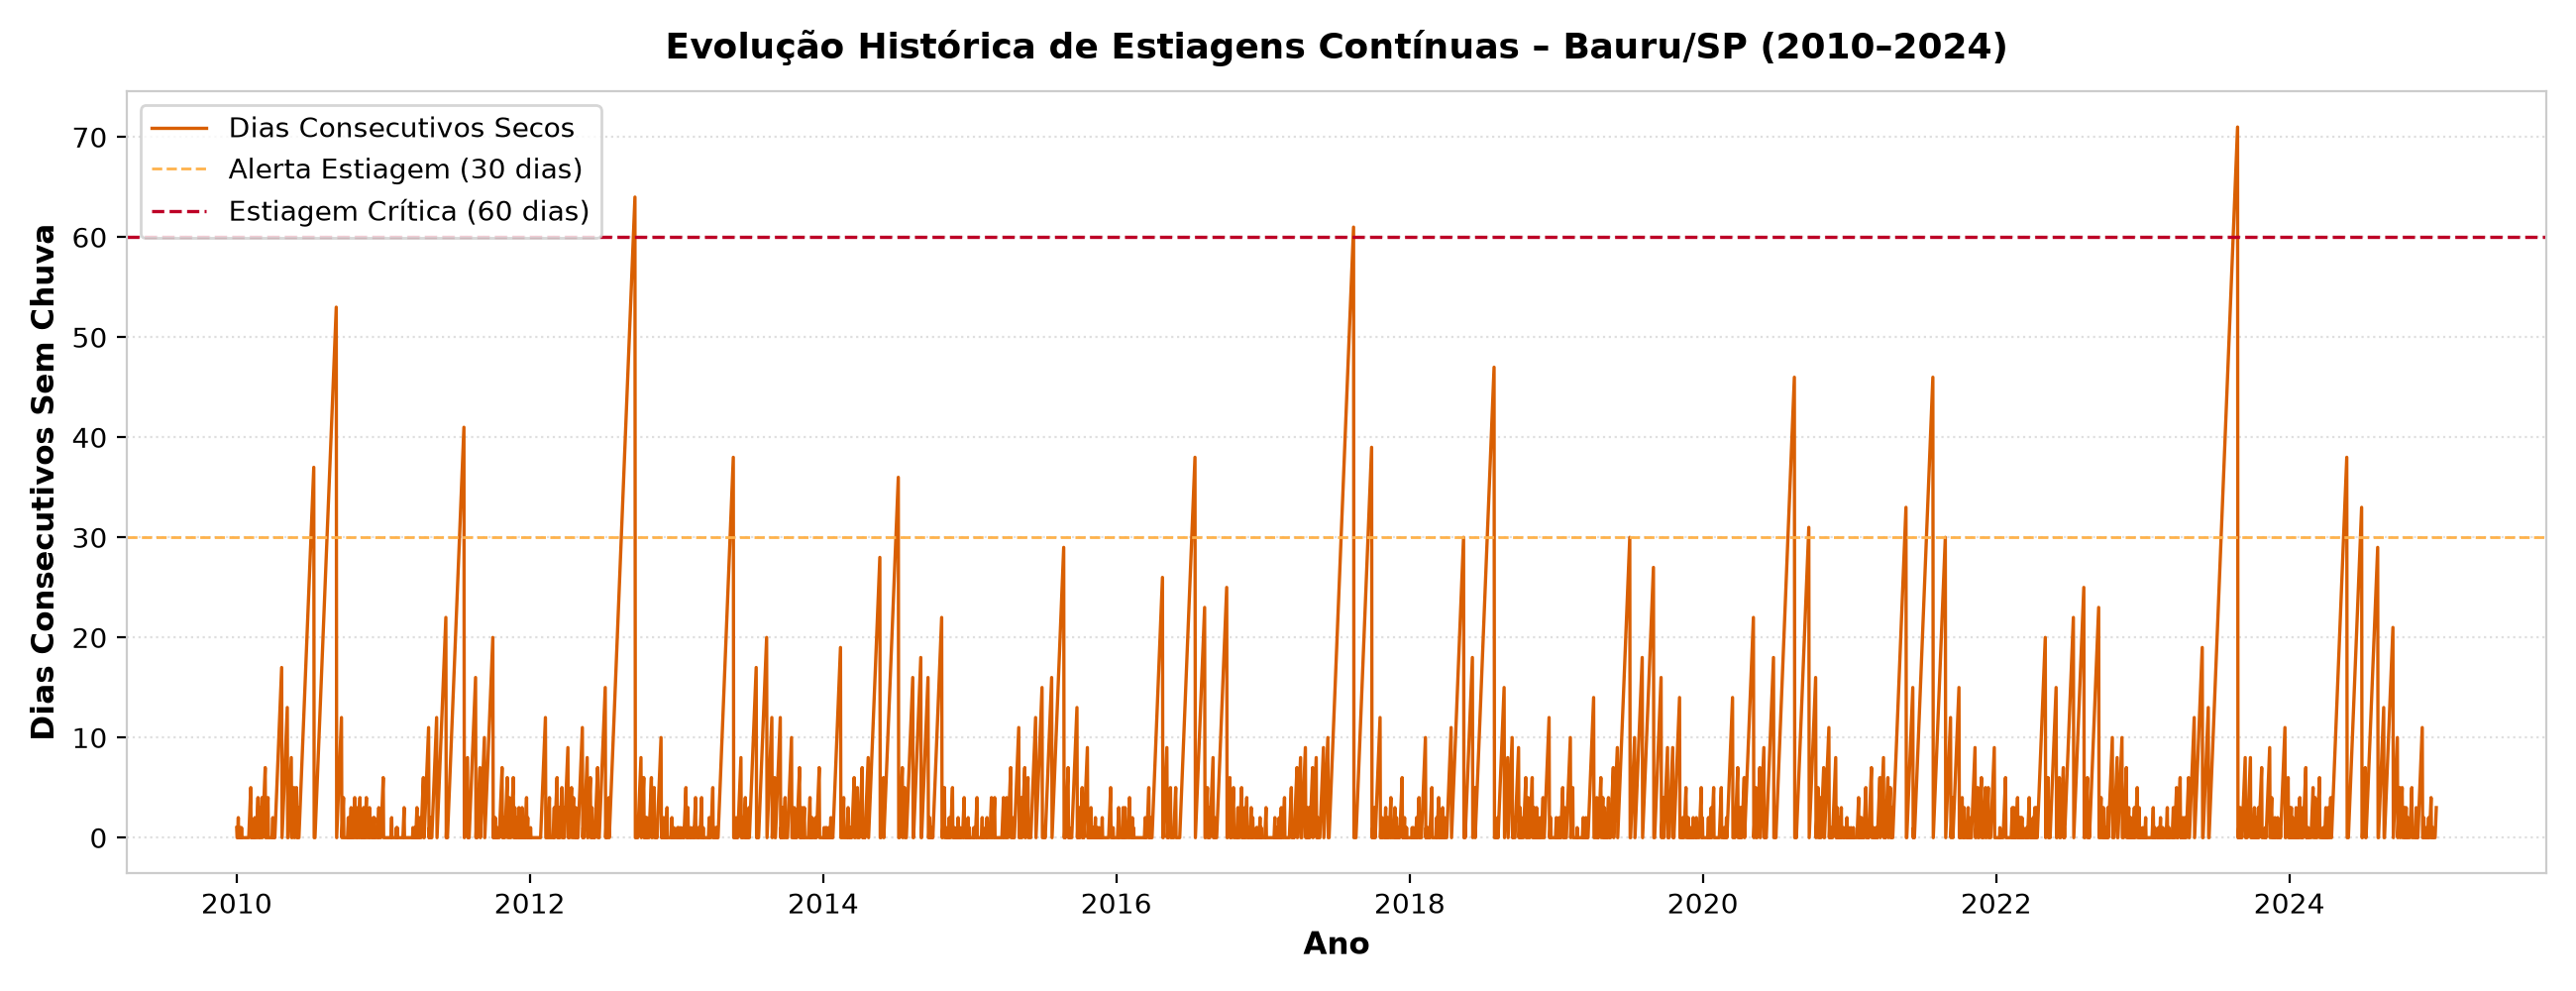

In [5]:
from IPython.display import Image, display

fig_paths = [
    '../reports/figures/fig01_climograma_bauru.png',
    '../reports/figures/fig02_anomalias_temperatura.png',
    '../reports/figures/fig03_boxplots_temperatura_mensal.png',
    '../reports/figures/fig04_heatmap_correlacoes.png',
    '../reports/figures/fig05_decomposicao_stl_temperatura.png',
    '../reports/figures/fig06_eventos_estiagem_dias_secos.png'
]

for p in fig_paths:
    print(f"Exibindo: {p}")
    display(Image(filename=p))